# Task 03: Feature Engineering & Preprocessing Pipeline

This notebook uses the existing `customer-churn-training.csv` dataset for RabTech Academy Task 03.

The dataset contains only 12 records, so preprocessing demonstrations and feature-importance results are educational and unstable. They must not be interpreted as production performance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load and inspect the actual dataset

In [2]:
DATA_FILE = Path.cwd().parent / "customer-churn-training.csv"
TARGET = "churned"
ID_COLUMN = "customer_id"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Could not find {DATA_FILE}")

data = pd.read_csv(DATA_FILE)
print(f"Dataset shape: {data.shape}")
print(f"Column names: {list(data.columns)}")
data.head()

Dataset shape: (12, 7)
Column names: ['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


### Basic quality checks

In [3]:
print("Data types:")
display(data.dtypes)
print("Missing values:")
display(data.isna().sum())
print(f"Duplicate rows: {data.duplicated().sum()}")
print("Numerical descriptive statistics:")
display(data.select_dtypes(include="number").describe())

Data types:


customer_id            str
tenure_months        int64
support_tickets      int64
monthly_spend_inr    int64
last_login_days      int64
plan_type              str
churned              int64
dtype: object

Missing values:


customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate rows: 0
Numerical descriptive statistics:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
count,12.000000,12.000000,12.000000,12.000000,12.000000
mean,12.166667,2.250000,915.666667,10.000000,0.416667
std,9.242524,1.602555,332.574895,9.095453,0.514929
min,1.000000,0.000000,499.000000,1.000000,0.000000
25%,5.500000,1.000000,724.000000,2.750000,0.000000
50%,9.500000,2.000000,899.000000,7.000000,0.000000
75%,18.500000,3.250000,1074.000000,14.750000,1.000000
max,30.000000,5.000000,1499.000000,30.000000,1.000000


## 3. Identify target and model features

In [4]:
if TARGET not in data.columns:
    raise ValueError(f"Expected target column {TARGET!r} is not present.")

feature_columns = [column for column in data.columns if column not in {TARGET, ID_COLUMN}]
categorical_features = data[feature_columns].select_dtypes(
    include=["str", "category", "bool"]
).columns.tolist()
numerical_features = data[feature_columns].select_dtypes(
    include="number"
).columns.tolist()

print(f"Target column: {TARGET}")
print(f"Excluded identifier: {ID_COLUMN if ID_COLUMN in data.columns else 'Not present'}")
print(f"Numerical features: {numerical_features}")
print(f"Categorical features: {categorical_features}")

Target column: churned
Excluded identifier: customer_id
Numerical features: ['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']
Categorical features: ['plan_type']


## 4. Leakage checks and split before preprocessing

The target and identifier are removed before model features are constructed. The train/test split happens before the `ColumnTransformer` is fitted, so scaling and encoding learn parameters only from training data.

In [5]:
X = data[feature_columns].copy()
y = data[TARGET].copy()

leakage_candidates = [
    column for column in feature_columns
    if "churn" in column.lower() or "target" in column.lower()
]
print(f"customer_id excluded from X: {ID_COLUMN not in X.columns}")
print(f"churned excluded from X: {TARGET not in X.columns}")
print(f"Name-based leakage candidates requiring review: {leakage_candidates or 'None detected'}")

if y.nunique() < 2:
    raise ValueError("At least two target classes are required for this analysis.")
if y.value_counts().min() < 2:
    raise ValueError("Each target class needs at least two records for a safe split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training rows: {len(X_train)}; testing rows: {len(X_test)}")

customer_id excluded from X: True
churned excluded from X: True
Name-based leakage candidates requiring review: None detected
Training rows: 9; testing rows: 3


## 5. Reusable preprocessing and modeling pipeline

Numerical columns are standardized. Categorical columns are one-hot encoded with `handle_unknown="ignore"`. The `Pipeline` ensures the preprocessing is fitted as part of training and can be reused consistently on test data.

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numerical_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

model_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

# Fit the complete pipeline only on training data.
model_pipeline.fit(X_train, y_train)
X_train_transformed = model_pipeline.named_steps["preprocess"].transform(X_train)
X_test_transformed = model_pipeline.named_steps["preprocess"].transform(X_test)

print(f"Transformed training shape: {X_train_transformed.shape}")
print(f"Transformed test shape: {X_test_transformed.shape}")
print(f"Test accuracy for pipeline smoke check: {accuracy_score(y_test, model_pipeline.predict(X_test)):.3f}")

Transformed training shape: (9, 7)
Transformed test shape: (3, 7)
Test accuracy for pipeline smoke check: 1.000


## 6. Correlation analysis

Correlation is shown only for the numerical columns actually present in the dataset and the numeric target. With 12 records, these relationships are descriptive and should not be treated as stable estimates.

,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
tenure_months,1.000000,-0.893032,0.868524,-0.826201,-0.760880
support_tickets,-0.893032,1.000000,-0.793155,0.941775,0.853786
monthly_spend_inr,0.868524,-0.793155,1.000000,-0.817452,-0.787426
last_login_days,-0.826201,0.941775,-0.817452,1.000000,0.854060
churned,-0.760880,0.853786,-0.787426,0.854060,1.000000


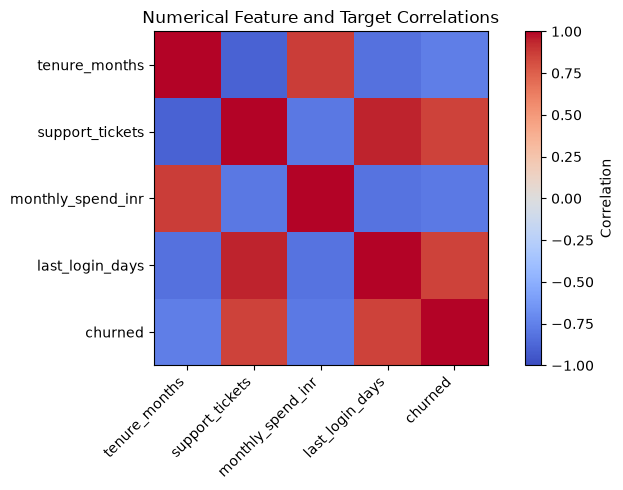

In [7]:
correlation_columns = numerical_features + [TARGET]
correlation_matrix = data[correlation_columns].corr()
display(correlation_matrix)

plt.figure(figsize=(8, 5))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_columns)), correlation_columns, rotation=45, ha="right")
plt.yticks(range(len(correlation_columns)), correlation_columns)
plt.title("Numerical Feature and Target Correlations")
plt.tight_layout()
plt.show()

## 7. Feature-importance analysis with mutual information

Mutual information is calculated on the transformed training data only. The reported names are transformed feature names, so categorical levels such as `plan_type_Basic` are individual encoded features. Because the training set has only 9 records, the rankings are exploratory and not statistically reliable.

In [8]:
transformed_feature_names = model_pipeline.named_steps["preprocess"].get_feature_names_out()
transformed_categorical_names = model_pipeline.named_steps["preprocess"].named_transformers_[
    "categorical"
].get_feature_names_out(categorical_features)
discrete_features = [name.startswith("categorical__") for name in transformed_feature_names]

mutual_information = mutual_info_classif(
    X_train_transformed,
    y_train,
    discrete_features=discrete_features,
    random_state=42,
)
feature_importance = (
    pd.DataFrame(
        {"transformed_feature": transformed_feature_names, "mutual_information": mutual_information}
    )
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)
print("Exploratory mutual-information ranking:")
display(feature_importance)
print(
    "Important features in this educational sample are the highest-ranked rows above; "
    "the ranking is not reliable enough for production decisions."
)

Exploratory mutual-information ranking:


,transformed_feature,mutual_information
0,categorical__plan_type_Basic,0.686962
1,numeric__tenure_months,0.606746
2,numeric__support_tickets,0.497487
3,numeric__monthly_spend_inr,0.427116
4,numeric__last_login_days,0.411243
5,categorical__plan_type_Pro,0.262619
6,categorical__plan_type_Standard,0.155811


Important features in this educational sample are the highest-ranked rows above; the ranking is not reliable enough for production decisions.


## Limitations and Responsible Use

- **Preprocessing and leakage prevention:** The target and `customer_id` are excluded from model features. The train/test split happens before the `ColumnTransformer` is fitted, and the reusable `Pipeline` learns scaling and encoding parameters from training data only.
- **Small dataset:** The CSV contains only 12 records, leaving 9 training rows and 3 test rows. Correlations, transformed shapes, accuracy, and feature rankings can change substantially when one record changes.
- **Feature-importance limitations:** Mutual-information estimates from 9 training records are exploratory, can be sensitive to the split, and do not establish causation or dependable feature importance. Encoded `plan_type` levels are shown as transformed features.
- **Production performance:** These results must not be treated as production performance. The available files do not establish sampling representativeness, prediction timing, label quality, or generalization to other customers.
- **Human review:** Any customer-related action requires appropriate human review. Model outputs should be treated as uncertain decision-support signals, not automatic decisions about customers, eligibility, access, pricing, or treatment.

## 1. Imports and dataset path